<a href="https://colab.research.google.com/github/yashvityagi/fetal-ultrasound-segmentation/blob/main/DataPreprocessing.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
# Setting working paths
import os
DATASET_DIR = '/content/drive/MyDrive/Ultrasound_Dataset/images'
MASK_OUTPUT_DIR = '/content/drive/MyDrive/Ultrasound_Dataset/masks'

os.makedirs(MASK_OUTPUT_DIR, exist_ok=True)
print(f"Images path: {DATASET_DIR}")
print(f"Masks will be saved to: {MASK_OUTPUT_DIR}")

Images path: /content/drive/MyDrive/Ultrasound_Dataset/images
Masks will be saved to: /content/drive/MyDrive/Ultrasound_Dataset/masks


In [ ]:
import os
import zipfile
import glob
import shutil
from google.colab import drive

# Mount Drive
# Check if drive is already mounted to avoid ValueError
if not os.path.exists('/content/drive/MyDrive'):
    drive.mount('/content/drive')
else:
    print("Google Drive already mounted.")

# 1. Define Paths based on your screenshot
# Checks if the zip file has .zip extension or no extension in drive name
BASE_DRIVE_DIR = '/content/drive/MyDrive/Ultrasound_Dataset'
# Check for both 'images.zip' and 'images' directory for flexibility
MAIN_ZIP_PATH = ''
if os.path.exists(os.path.join(BASE_DRIVE_DIR, 'images.zip')):
    MAIN_ZIP_PATH = os.path.join(BASE_DRIVE_DIR, 'images.zip')
elif os.path.exists(os.path.join(BASE_DRIVE_DIR, 'images')):
    MAIN_ZIP_PATH = os.path.join(BASE_DRIVE_DIR, 'images')

EXTRACT_TEMP_DIR = '/content/dataset_raw'
FINAL_IMAGES_DIR = '/content/dataset_images'
MASK_OUTPUT_DIR = os.path.join(BASE_DRIVE_DIR, 'masks')

os.makedirs(EXTRACT_TEMP_DIR, exist_ok=True)
os.makedirs(FINAL_IMAGES_DIR, exist_ok=True)
os.makedirs(MASK_OUTPUT_DIR, exist_ok=True)

# 2. Extract Main Zip File
if MAIN_ZIP_PATH and os.path.exists(MAIN_ZIP_PATH):
    print(f"Extracting main zip from: {MAIN_ZIP_PATH} ...")
    if zipfile.is_zipfile(MAIN_ZIP_PATH):
        with zipfile.ZipFile(MAIN_ZIP_PATH, 'r') as zip_ref:
            zip_ref.extractall(EXTRACT_TEMP_DIR)
        print("Main zip extracted successfully!")
    else:
        # If it's a directory, we assume it's already extracted or contains direct images
        print(f"'{MAIN_ZIP_PATH}' is a directory, assuming images are directly available or previously extracted.")
        # Optionally, copy contents if not already in EXTRACT_TEMP_DIR
        # For simplicity, we'll proceed assuming images will be found by glob later
else:
    print(f"Warning: Neither 'images.zip' nor 'images' directory found at {BASE_DRIVE_DIR}. Skipping main zip extraction.")

# 3. Handle Class-wise Sub-ZIPs recursively
def extract_nested_zips(directory):
    while True:
        sub_zips = glob.glob(os.path.join(directory, "**/*.zip"), recursive=True)
        if not sub_zips:
            break
        for z_file in sub_zips:
            target_folder = os.path.splitext(z_file)[0]
            print(f"Extracting sub-zip: {os.path.basename(z_file)}")
            with zipfile.ZipFile(z_file, 'r') as zip_ref:
                zip_ref.extractall(target_folder)
            os.remove(z_file) # Clean up sub-zip after extracting

print("Checking for class-wise sub-zips...")
extract_nested_zips(EXTRACT_TEMP_DIR)
print("All nested class zip files unpacked!")

# 4. Consolidate all images into FINAL_IMAGES_DIR with clean names
valid_extensions = ("*.png", "*.jpg", "*.jpeg", "*.bmp", "*.PNG", "*.JPG", "*.JPEG")
all_images = []

for ext in valid_extensions:
    all_images.extend(glob.glob(os.path.join(EXTRACT_TEMP_DIR, f"**/{ext}"), recursive=True))

print(f"\nTotal image files discovered across all classes: {len(all_images)}")

for img_path in all_images:
    # Retain sub-folder (class) information in the filename to avoid name collisions
    rel_path = os.path.relpath(img_path, EXTRACT_TEMP_DIR)
    flat_filename = rel_path.replace("/", "_").replace("\\", "_")

    shutil.copy(img_path, os.path.join(FINAL_IMAGES_DIR, flat_filename))

print(f"✅ All images are ready at: {FINAL_IMAGES_DIR}")
print(f"✅ Masks will be saved to: {MASK_OUTPUT_DIR}")

Google Drive already mounted.
Extracting main zip from: /content/drive/MyDrive/Ultrasound_Dataset/images.zip ...
Main zip extracted successfully!
Checking for class-wise sub-zips...
Extracting sub-zip: Trans-ventricular-orginal-size.zip
Extracting sub-zip: Trans-cerebellum.zip
Extracting sub-zip: Diverse Fetal Head Images-orginal-image.zip
Extracting sub-zip: Trans-thalamic-orginal-size.zip
Extracting sub-zip: Trans-ventricular.zip
Extracting sub-zip: Trans-cerebellum-orginal-size.zip
Extracting sub-zip: Trans-thalamic.zip
Extracting sub-zip: Diverse Fetal Head Images.zip
Extracting sub-zip: Trans-thalamic-Cityscapes.zip
Extracting sub-zip: Trans-thalamic-CVAT.zip
Extracting sub-zip: Trans-thalamic-Datumaro.zip
Extracting sub-zip: Trans-thalamic-ICDAR-Localization.zip
Extracting sub-zip: Trans-thalamic-YOLO.zip
Extracting sub-zip: Trans-thalamic-Segmentation.zip
Extracting sub-zip: Trans-thalamic-PASCAL.zip
Extracting sub-zip: Trans-thalamic-LabelMe.zip
Extracting sub-zip: Trans-thalam

In [ ]:
import os
import shutil

# List of keywords to identify dataset types
keywords = [
    "TFRecord", "PASCAL-VOC", "COCO", "YOLO-1.1", "gtFine", "LabelMe",
    "ICDAR-Localization", "Segmentation", "Datumaro", "OpenImage",
    "Cityscapes", "YOLO", "CVAT", "PASCAL"
]

# Directory where all consolidated images are located
final_images_dir = FINAL_IMAGES_DIR # From previous cell

# Get a list of all image files in the consolidated directory
all_image_files = [f for f in os.listdir(final_images_dir) if os.path.isfile(os.path.join(final_images_dir, f))]

print(f"Starting organization of {len(all_image_files)} images...")

# Create a dictionary to store counts of files moved to each category
category_counts = {}

for image_filename in all_image_files:
    moved = False
    for keyword in keywords:
        # Normalize keyword for folder name (remove '*' if present, replace '-' with '_', ensure valid folder name)
        clean_keyword = keyword.replace('*', '').replace('-', '_').replace('.', '_')

        # Check if the keyword (case-insensitive) is in the filename
        if clean_keyword.lower() in image_filename.lower():
            target_subdir = os.path.join(final_images_dir, clean_keyword)
            os.makedirs(target_subdir, exist_ok=True)

            source_path = os.path.join(final_images_dir, image_filename)
            destination_path = os.path.join(target_subdir, image_filename)

            shutil.move(source_path, destination_path)

            category_counts[clean_keyword] = category_counts.get(clean_keyword, 0) + 1
            moved = True
            break # Move to the next image once a keyword match is found

    if not moved:
        # Optionally, you can move uncategorized images to a 'Uncategorized' folder
        # For now, they will simply remain in the `final_images_dir` if no keyword matches
        pass

print("\nOrganization complete!")
print("Summary of images moved:")
if not category_counts:
    print("  No images matched any specified keywords.")
for category, count in category_counts.items():
    print(f"  - {category}: {count} images")

# List any remaining files in the main FINAL_IMAGES_DIR (uncategorized)
remaining_files = [f for f in os.listdir(final_images_dir) if os.path.isfile(os.path.join(final_images_dir, f))]
if remaining_files:
    print(f"\n{len(remaining_files)} images remain uncategorized in: {final_images_dir}")
else:
    print(f"\nAll images have been categorized.")

Starting organization of 44895 images...

Organization complete!
Summary of images moved:
  - gtFine: 11496 images
  - Segmentation: 15248 images
  - OpenImage: 5300 images
  - LabelMe: 3792 images

9059 images remain uncategorized in: /content/dataset_images


In [ ]:
import os
import shutil

# Directory where all consolidated and some uncategorized images are located
final_images_dir = FINAL_IMAGES_DIR # From previous cell

# Create the 'Uncategorized' folder if it doesn't exist
uncategorized_dir = os.path.join(final_images_dir, 'Uncategorized')
os.makedirs(uncategorized_dir, exist_ok=True)

# Get a list of all files currently in the main final_images_dir (these are the remaining uncategorized ones)
remaining_uncategorized_files = [f for f in os.listdir(final_images_dir) if os.path.isfile(os.path.join(final_images_dir, f))]

print(f"Moving {len(remaining_uncategorized_files)} uncategorized images to '{uncategorized_dir}'...")

moved_count = 0
for filename in remaining_uncategorized_files:
    source_path = os.path.join(final_images_dir, filename)
    destination_path = os.path.join(uncategorized_dir, filename)
    shutil.move(source_path, destination_path)
    moved_count += 1

print(f"Successfully moved {moved_count} images to '{uncategorized_dir}'.")

# Verify that no files remain directly in final_images_dir
final_check_remaining = [f for f in os.listdir(final_images_dir) if os.path.isfile(os.path.join(final_images_dir, f))]
if not final_check_remaining:
    print("All images have now been categorized or moved to 'Uncategorized'.")
else:
    print(f"Warning: {len(final_check_remaining)} files still remain in {final_images_dir}. This should not happen.")

Moving 9059 uncategorized images to '/content/dataset_images/Uncategorized'...
Successfully moved 9059 images to '/content/dataset_images/Uncategorized'.
All images have now been categorized or moved to 'Uncategorized'.


Displaying 5 random images from '/content/dataset_images/Segmentation':



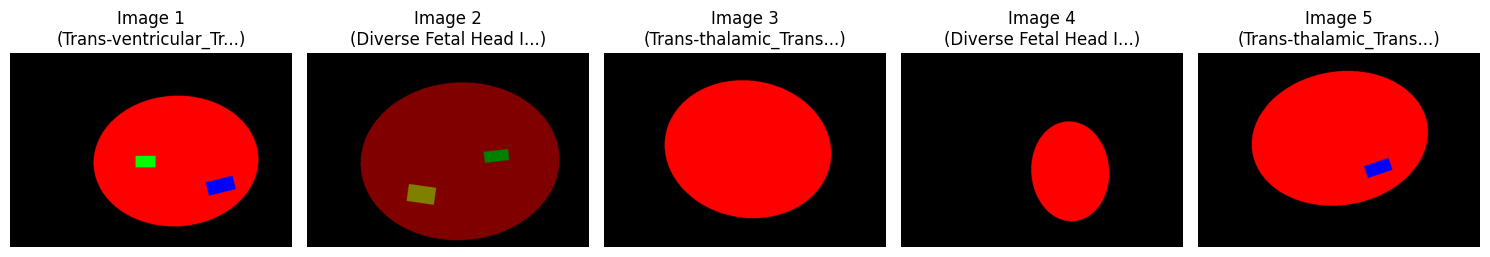

In [ ]:
import os
import random
import matplotlib.pyplot as plt
from PIL import Image

# Define the path to the Segmentation folder
segmentation_dir = os.path.join(FINAL_IMAGES_DIR, 'Segmentation')

# Get a list of all image files in the Segmentation folder
# Assuming valid image extensions are already handled during consolidation
image_files = [f for f in os.listdir(segmentation_dir) if f.lower().endswith(('.png', '.jpg', '.jpeg', '.bmp'))]

if not image_files:
    print(f"No image files found in '{segmentation_dir}'.")
else:
    # Select a random sample of 5 images
    sample_size = min(5, len(image_files)) # Ensure we don't try to sample more than available images
    random_sample = random.sample(image_files, sample_size)

    print(f"Displaying {sample_size} random images from '{segmentation_dir}':\n")

    plt.figure(figsize=(15, 5)) # Adjust figure size as needed
    for i, img_name in enumerate(random_sample):
        img_path = os.path.join(segmentation_dir, img_name)
        img = Image.open(img_path)

        plt.subplot(1, sample_size, i + 1)
        plt.imshow(img)
        plt.title(f"Image {i+1}\n({img_name[:20]}...)") # Display first 20 chars of filename
        plt.axis('off')

    plt.tight_layout()
    plt.show()

Displaying a random sample of images from '/content/dataset_images/Uncategorized':



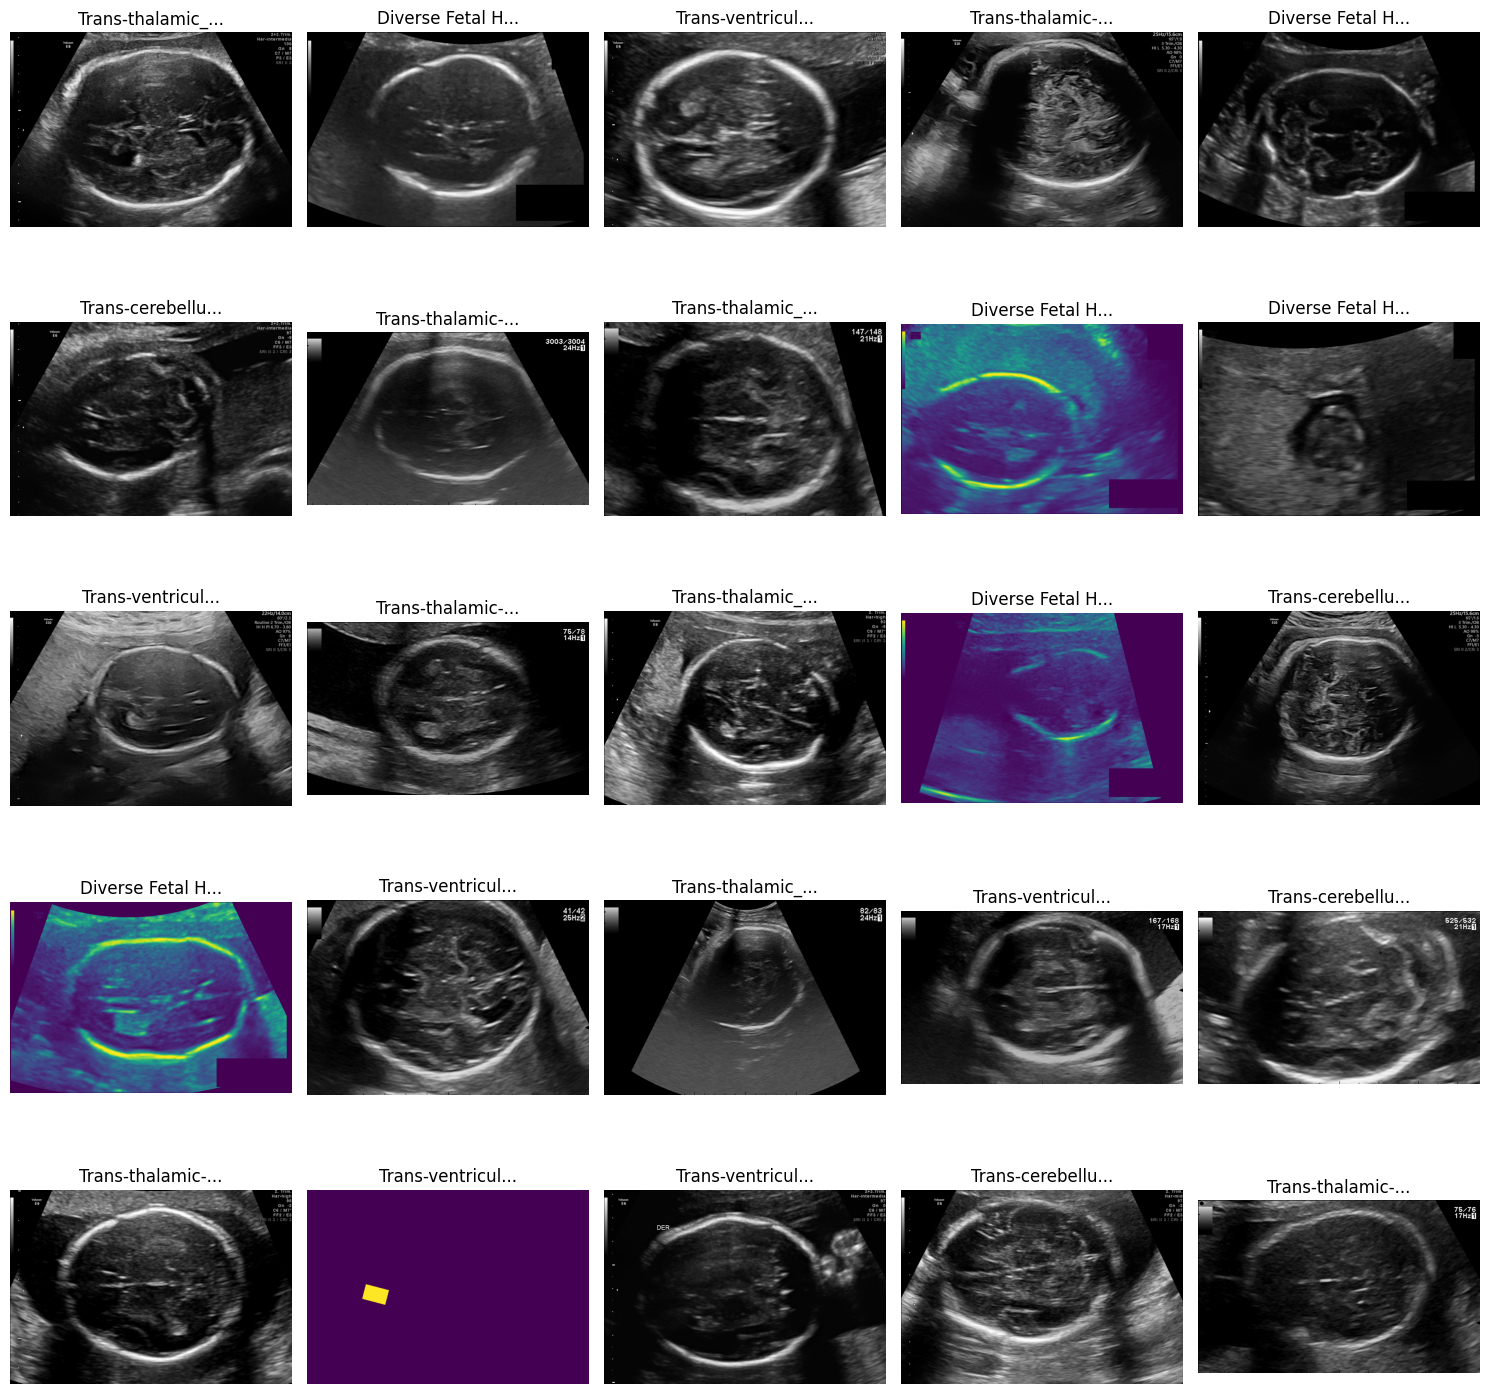

In [ ]:
import os
import matplotlib.pyplot as plt
from PIL import Image
import random

# Define the path to the Uncategorized folder
uncategorized_dir = os.path.join(FINAL_IMAGES_DIR, 'Uncategorized')

# Get a list of all image files in the Uncategorized folder
image_files = [f for f in os.listdir(uncategorized_dir) if f.lower().endswith(('.png', '.jpg', '.jpeg', '.bmp'))]

if not image_files:
    print(f"No image files found in '{uncategorized_dir}'.")
else:
    print(f"Displaying a random sample of images from '{uncategorized_dir}':\n")

    # Limit the number of images to display to avoid excessively long output
    max_display_images = 25 # You can adjust this number

    sample_size = min(max_display_images, len(image_files))
    display_files = random.sample(image_files, sample_size)

    cols = 5  # Number of columns in the grid
    rows = (sample_size + cols - 1) // cols # Calculate rows needed

    plt.figure(figsize=(cols * 3, rows * 3)) # Adjust figure size dynamically

    for i, img_name in enumerate(display_files):
        img_path = os.path.join(uncategorized_dir, img_name)
        try:
            img = Image.open(img_path)
            plt.subplot(rows, cols, i + 1)
            plt.imshow(img)
            plt.title(f"{img_name[:15]}...") # Display first 15 chars of filename
            plt.axis('off')
        except Exception as e:
            print(f"Could not open image {img_name}: {e}")

    plt.tight_layout()
    plt.show()

In [ ]:
import os
import random

uncategorized_dir = os.path.join(FINAL_IMAGES_DIR, 'Uncategorized')
image_files = [f for f in os.listdir(uncategorized_dir) if f.lower().endswith(('.png', '.jpg', '.jpeg', '.bmp'))]

if not image_files:
    print(f"No image files found in '{uncategorized_dir}'.")
else:
    sample_size = min(20, len(image_files))
    random_filenames = random.sample(image_files, sample_size)

    print(f"Random sample of {sample_size} filenames from '{uncategorized_dir}':\n")
    for filename in random_filenames:
        print(filename)

Random sample of 20 filenames from '/content/dataset_images/Uncategorized':

Diverse Fetal Head Images-orginal-image_Diverse Fetal Head Images-orginal-image_472_HC.png
Diverse Fetal Head Images-orginal-image_Diverse Fetal Head Images-orginal-image_781_HC.png
Trans-thalamic_Trans-thalamic_Trans-thalamic_Patient01419_Plane3_4_of_4.png
Diverse Fetal Head Images-orginal-image_Diverse Fetal Head Images-orginal-image_096_HC.png
Trans-thalamic_Trans-thalamic_Trans-thalamic_Patient01501_Plane3_2_of_5.png
Diverse Fetal Head Images-orginal-image_Diverse Fetal Head Images-orginal-image_505_HC.png
Trans-thalamic-orginal-size_Trans-thalamic-orginal-size_Patient01498_Plane3_1_of_1.png
Trans-thalamic_Trans-thalamic_Trans-thalamic_Patient01718_Plane3_2_of_4.png
Trans-thalamic-orginal-size_Trans-thalamic-orginal-size_Patient00760_Plane3_1_of_4.png
Trans-thalamic-orginal-size_Trans-thalamic-orginal-size_Patient01480_Plane3_5_of_6.png
Trans-ventricular_Trans-ventricular_Trans-ventricular-Open-Images_mask

In [ ]:
import os
import shutil

uncategorized_dir = os.path.join(FINAL_IMAGES_DIR, 'Uncategorized')
segmentation_dir = os.path.join(FINAL_IMAGES_DIR, 'Segmentation')

# Ensure the Segmentation directory exists
os.makedirs(segmentation_dir, exist_ok=True)

image_files = [f for f in os.listdir(uncategorized_dir) if f.lower().endswith(('.png', '.jpg', '.jpeg', '.bmp'))]

if not image_files:
    print(f"No image files found in '{uncategorized_dir}'.")
else:
    moved_count = 0
    print(f"Searching for 'Open-Images_masks' in {len(image_files)} uncategorized files...")

    for filename in image_files:
        if 'open-images_masks' in filename.lower():
            source_path = os.path.join(uncategorized_dir, filename)
            destination_path = os.path.join(segmentation_dir, filename)
            shutil.move(source_path, destination_path)
            moved_count += 1

    print(f"Moved {moved_count} images containing 'Open-Images_masks' to the 'Segmentation' folder.")
    if moved_count > 0:
        print("You may want to re-check the 'Uncategorized' folder for other patterns or display a new sample.")

Searching for 'Open-Images_masks' in 9059 uncategorized files...
Moved 1279 images containing 'Open-Images_masks' to the 'Segmentation' folder.
You may want to re-check the 'Uncategorized' folder for other patterns or display a new sample.


In [ ]:
import os
import random

# Define the path to the Segmentation folder
segmentation_dir = os.path.join(FINAL_IMAGES_DIR, 'Segmentation')

# Get a list of all image files in the Segmentation folder
image_files_seg = [f for f in os.listdir(segmentation_dir) if os.path.isfile(os.path.join(segmentation_dir, f))]

if not image_files_seg:
    print(f"No image files found in '{segmentation_dir}'.")
else:
    sample_size = min(10, len(image_files_seg))
    random_filenames_seg = random.sample(image_files_seg, sample_size)

    print(f"Random sample of {sample_size} filenames from '{segmentation_dir}':\n")
    for filename in random_filenames_seg:
        print(filename)

Random sample of 10 filenames from '/content/dataset_images/Segmentation':

Diverse Fetal Head Images_Diverse Fetal Head Images_Test-Dataset-Segmentation_SegmentationObject_236_HC.png
Trans-cerebellum_Trans-cerebellum_Trans-cerebellum-PASCAL_SegmentationObject_Patient01228_Plane3_1_of_2.png
Trans-thalamic_Trans-thalamic_Trans-thalamic-Segmentation_SegmentationObject_Patient00846_Plane3_1_of_2.png
Trans-ventricular_Trans-ventricular_Trans-ventricular-Open-Images_masks_default_patient01696_plane3_3_of_3_csp_00000002.png
Trans-thalamic_Trans-thalamic_Trans-thalamic-Segmentation_SegmentationClass_Patient01649_Plane3_2_of_5.png
Trans-cerebellum_Trans-cerebellum_Trans-cerebellum-PASCAL_SegmentationObject_Patient00996_Plane3_1_of_2.png
Trans-thalamic_Trans-thalamic_Trans-thalamic-PASCAL_SegmentationObject_Patient01563_Plane3_1_of_3.png
Trans-thalamic_Trans-thalamic_Trans-thalamic-Segmentation_SegmentationClass_Patient01155_Plane3_3_of_6.png
Trans-cerebellum_Trans-cerebellum_Trans-cerebellum-S

In [ ]:
import os
import random

# Ensure FINAL_IMAGES_DIR is defined
FINAL_IMAGES_DIR = '/content/dataset_images'

uncategorized_dir = os.path.join(FINAL_IMAGES_DIR, 'Uncategorized')
image_files = [f for f in os.listdir(uncategorized_dir) if f.lower().endswith(('.png', '.jpg', '.jpeg', '.bmp'))]

if not image_files:
    print(f"No image files found in '{uncategorized_dir}'. Cannot proceed with search.")
else:
    # Select a random image from the uncategorized folder
    selected_image_name = random.choice(image_files)
    print(f"Selected a random image from 'Uncategorized': {selected_image_name}\n")

    # Extract the base name (without extension and common suffixes)
    base_name = os.path.splitext(selected_image_name)[0]
    # Remove potential existing mask or category suffixes for a cleaner base name
    for keyword in ['_mask', '_masks', '_segmentation', '_label', '_seg', 'TFRecord', 'PASCAL-VOC', 'COCO', 'YOLO-1.1', 'gtFine', 'LabelMe', 'ICDAR-Localization', 'Segmentation', 'Datumaro', 'OpenImage', 'Cityscapes', 'YOLO', 'CVAT', 'PASCAL', 'Open-Images_masks']:
        if keyword.lower() in base_name.lower():
            base_name = base_name.lower().replace(keyword.lower(), '').strip('_').strip()

    print(f"Searching for files related to base name: '{base_name}' in '{FINAL_IMAGES_DIR}' and its subfolders...\n")

    found_files = []
    # Iterate through all files in FINAL_IMAGES_DIR and its subdirectories
    for root, _, files in os.walk(FINAL_IMAGES_DIR):
        for file in files:
            # Check for direct matches or base name matches
            if selected_image_name.lower() in file.lower() or base_name.lower() in file.lower():
                found_files.append(os.path.join(root, file))

    if found_files:
        print(f"Found {len(found_files)} related files:")
        for f_path in found_files:
            print(f_path)
    else:
        print(f"No related files found for '{selected_image_name}' or base name '{base_name}' in '{FINAL_IMAGES_DIR}'.")

Selected a random image from 'Uncategorized': Trans-ventricular_Trans-ventricular_Trans-ventricular_Patient01524_Plane3_4_of_4.png

Searching for files related to base name: 'Trans-ventricular_Trans-ventricular_Trans-ventricular_Patient01524_Plane3_4_of_4' in '/content/dataset_images' and its subfolders...

Found 1 related files:
/content/dataset_images/Uncategorized/Trans-ventricular_Trans-ventricular_Trans-ventricular_Patient01524_Plane3_4_of_4.png


In [ ]:
import os

print(f"Summary of folders and file counts in '{FINAL_IMAGES_DIR}':")
total_files_in_subfolders = 0

# Iterate through each item in FINAL_IMAGES_DIR
for item in os.listdir(FINAL_IMAGES_DIR):
    item_path = os.path.join(FINAL_IMAGES_DIR, item)

    # Check if it's a directory
    if os.path.isdir(item_path):
        # Count files within this directory
        file_count = len([f for f in os.listdir(item_path) if os.path.isfile(os.path.join(item_path, f))])
        print(f"  - {item}: {file_count} files")
        total_files_in_subfolders += file_count

print(f"\nTotal files accounted for in categorized folders: {total_files_in_subfolders}")

Summary of folders and file counts in '/content/dataset_images':
  - gtFine: 11496 files
  - OpenImage: 5300 files
  - Segmentation: 16527 files
  - LabelMe: 3792 files
  - Uncategorized: 7780 files

Total files accounted for in categorized folders: 44895


Selected mask: Diverse Fetal Head Images_Diverse Fetal Head Images_Test-Dataset-PASCAL_SegmentationClass_339_HC.png
Searching for potential original image for: Diverse Fetal Head Images_Diverse Fetal Head Images_Test-Dataset_339_HC (derived from mask name)
Could not find a matching original image for mask: Diverse Fetal Head Images_Diverse Fetal Head Images_Test-Dataset-PASCAL_SegmentationClass_339_HC.png


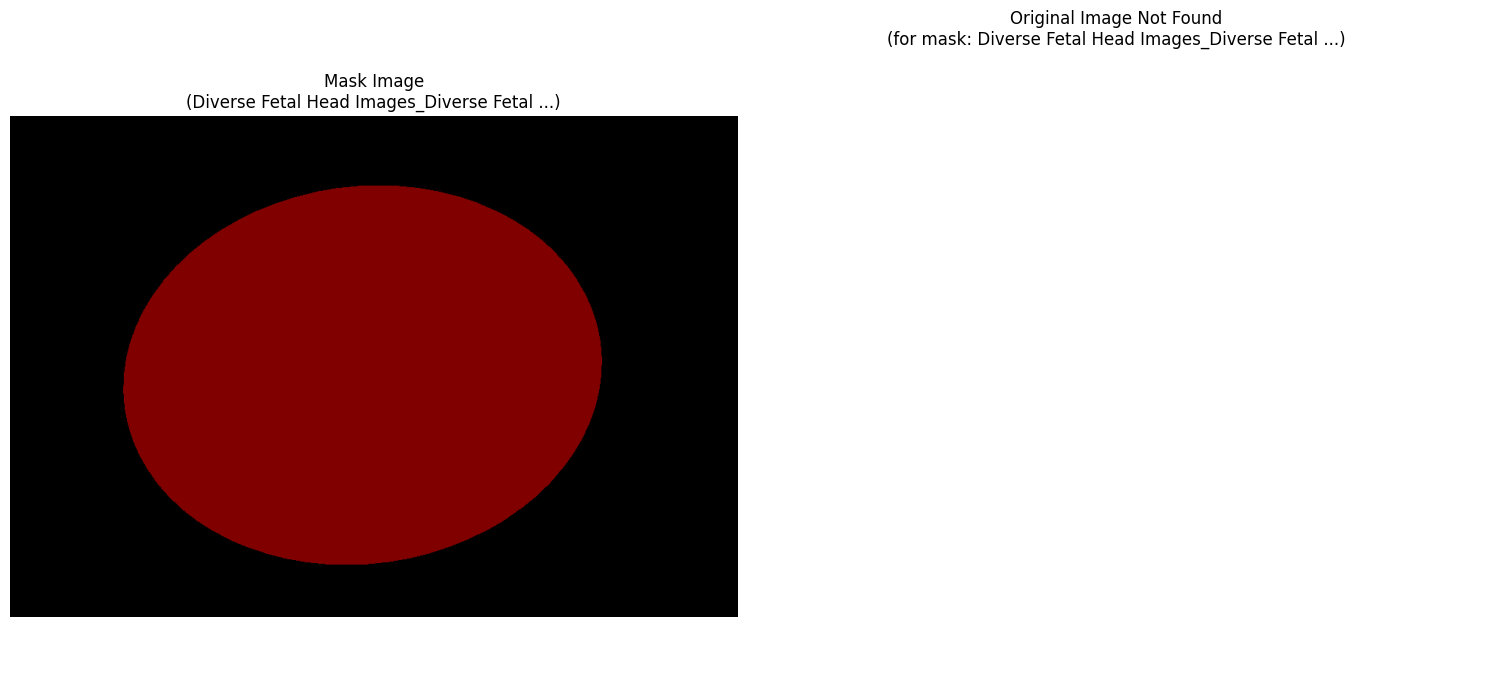

In [ ]:
import os
import random
import matplotlib.pyplot as plt
from PIL import Image

# Ensure FINAL_IMAGES_DIR is defined
FINAL_IMAGES_DIR = '/content/dataset_images'
segmentation_dir = os.path.join(FINAL_IMAGES_DIR, 'Segmentation')

# Get a list of all image files (which are masks) in the Segmentation folder
mask_files = [f for f in os.listdir(segmentation_dir) if f.lower().endswith(('.png', '.jpg', '.jpeg', '.bmp'))]

if not mask_files:
    print(f"No mask images found in '{segmentation_dir}'. Cannot proceed.")
else:
    # Select a random mask image
    selected_mask_name = random.choice(mask_files)
    selected_mask_path = os.path.join(segmentation_dir, selected_mask_name)
    print(f"Selected mask: {selected_mask_name}")

    # --- Infer potential original image filename ---
    # Common mask indicators to remove from the filename
    mask_indicators = [
        '-PASCAL_SegmentationClass', '-Segmentation_SegmentationObject', '-Open-Images_masks_default',
        '-Test-Dataset-Segmentation_SegmentationClass', '-Test-Dataset-PASCAL_SegmentationClass',
        '-PASCAL-VOC _SegmentationObject', '-PASCAL-VOC _SegmentationClass',
        '_mask', '_masks', '_segmentation', '_label', '_seg',
        'TFRecord', 'PASCAL-VOC', 'COCO', 'YOLO-1.1', 'gtFine', 'LabelMe',
        'ICDAR-Localization', 'Segmentation', 'Datumaro', 'OpenImage',
        'Cityscapes', 'YOLO', 'CVAT', 'PASCAL', 'Open-Images_masks'
    ]

    # Create a base name by removing file extension
    base_name_without_ext = os.path.splitext(selected_mask_name)[0]
    original_image_base_name = base_name_without_ext

    # Iteratively remove mask indicators (case-insensitive)
    for indicator in mask_indicators:
        original_image_base_name = original_image_base_name.replace(indicator, '')
        original_image_base_name = original_image_base_name.replace(indicator.lower(), '')

    # Clean up any residual underscores or spaces that might result from removal
    original_image_base_name = original_image_base_name.strip('_ ').strip()

    # Attempt to reconstruct the original image filename with various extensions
    possible_original_image_names = [
        original_image_base_name + '.png',
        original_image_base_name + '.jpg',
        original_image_base_name + '.jpeg',
        original_image_base_name + '.bmp'
    ]

    found_original_image_path = None
    print(f"Searching for potential original image for: {original_image_base_name} (derived from mask name)")

    # Search for the inferred original image in all subfolders of FINAL_IMAGES_DIR
    for root, _, files in os.walk(FINAL_IMAGES_DIR):
        for file in files:
            if file in possible_original_image_names:
                found_original_image_path = os.path.join(root, file)
                break
        if found_original_image_path:
            break

    # --- Display images ---
    plt.figure(figsize=(15, 7))

    # Display the mask image
    plt.subplot(1, 2, 1)
    try:
        mask_img = Image.open(selected_mask_path)
        plt.imshow(mask_img)
        plt.title(f"Mask Image\n({selected_mask_name[:40]}...)")
        plt.axis('off')
    except Exception as e:
        plt.title(f"Error loading mask: {e}")
        plt.axis('off')

    # Display the original image if found
    plt.subplot(1, 2, 2)
    if found_original_image_path:
        try:
            original_img = Image.open(found_original_image_path)
            plt.imshow(original_img)
            plt.title(f"Original Image\n({os.path.basename(found_original_image_path)[:40]}...)")
            plt.axis('off')
            print(f"Found original image: {os.path.basename(found_original_image_path)} in {os.path.dirname(found_original_image_path)}")
        except Exception as e:
            plt.title(f"Error loading original image: {e}")
            plt.axis('off')
            print(f"Error loading original image {os.path.basename(found_original_image_path)}: {e}")
    else:
        plt.title(f"Original Image Not Found\n(for mask: {selected_mask_name[:40]}...)")
        plt.axis('off')
        print(f"Could not find a matching original image for mask: {selected_mask_name}")

    plt.tight_layout()
    plt.show()

Attempting to display image-mask pairs for a sample of 5 images.

Processing mask: Trans-thalamic_Trans-thalamic_Trans-thalamic-Segmentation_SegmentationClass_Patient01623_Plane3_2_of_2.png
  Searching for original image for derived base names (case-insensitive search): ['trans_thalamic_trans_thalamic_trans_thalamic_patient01623_plane3_2_of_2', 'trans-thalamic-trans-thalamic-trans-thalamic-patient01623-plane3-2-of-2']
  Could not find a matching original image for mask: Trans-thalamic_Trans-thalamic_Trans-thalamic-Segmentation_SegmentationClass_Patient01623_Plane3_2_of_2.png


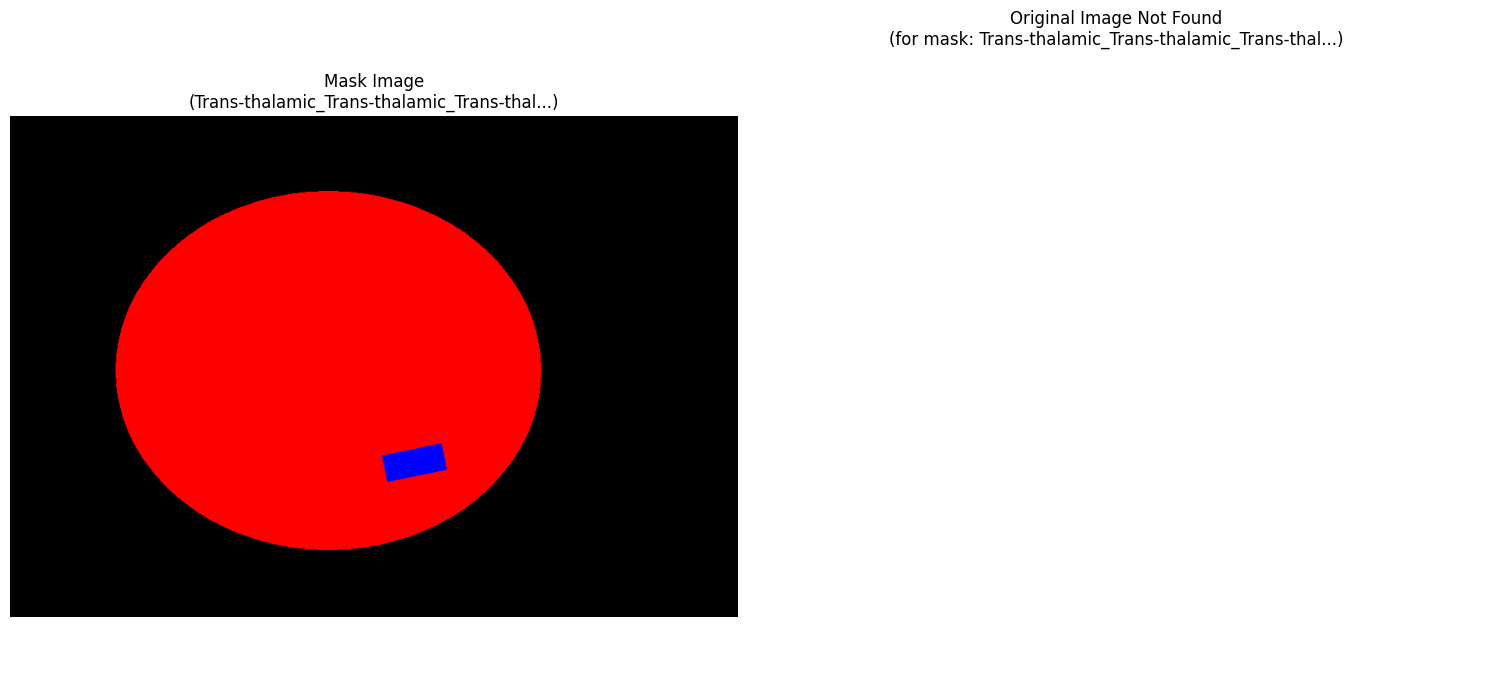


Processing mask: Diverse Fetal Head Images_Diverse Fetal Head Images_Test-Dataset-Segmentation_SegmentationObject_785_2HC.png
  Searching for original image for derived base names (case-insensitive search): ['diverse_fetal_head_images_diverse_fetal_head_images_785_2hc', 'diverse-fetal-head-images-diverse-fetal-head-images-785-2hc']
  Could not find a matching original image for mask: Diverse Fetal Head Images_Diverse Fetal Head Images_Test-Dataset-Segmentation_SegmentationObject_785_2HC.png


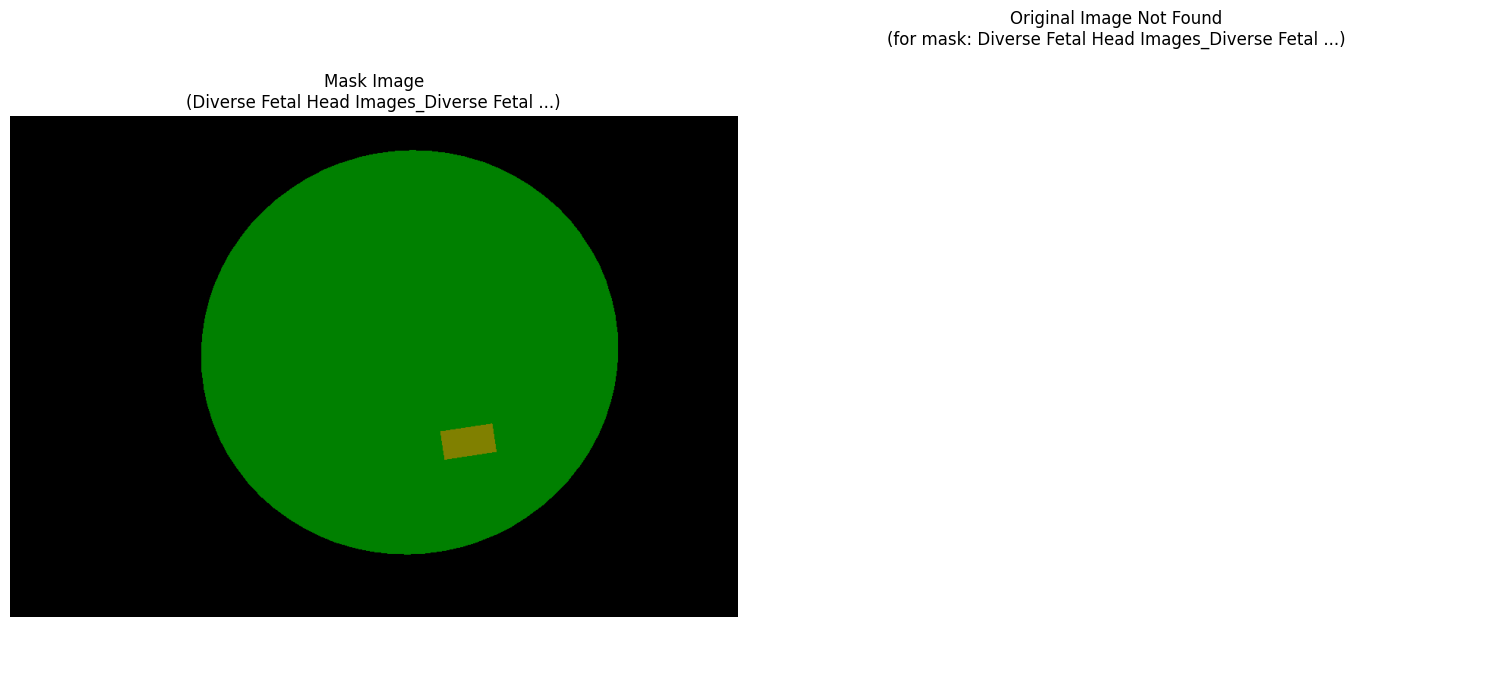


Processing mask: Trans-ventricular_Trans-ventricular_Trans-ventricular-PASCAL-VOC _SegmentationClass_Patient01491_Plane3_5_of_5.png
  Searching for original image for derived base names (case-insensitive search): ['trans-ventricular-trans-ventricular-trans-ventricular-patient01491-plane3-5-of-5', 'trans_ventricular_trans_ventricular_trans_ventricular_patient01491_plane3_5_of_5']
  Could not find a matching original image for mask: Trans-ventricular_Trans-ventricular_Trans-ventricular-PASCAL-VOC _SegmentationClass_Patient01491_Plane3_5_of_5.png


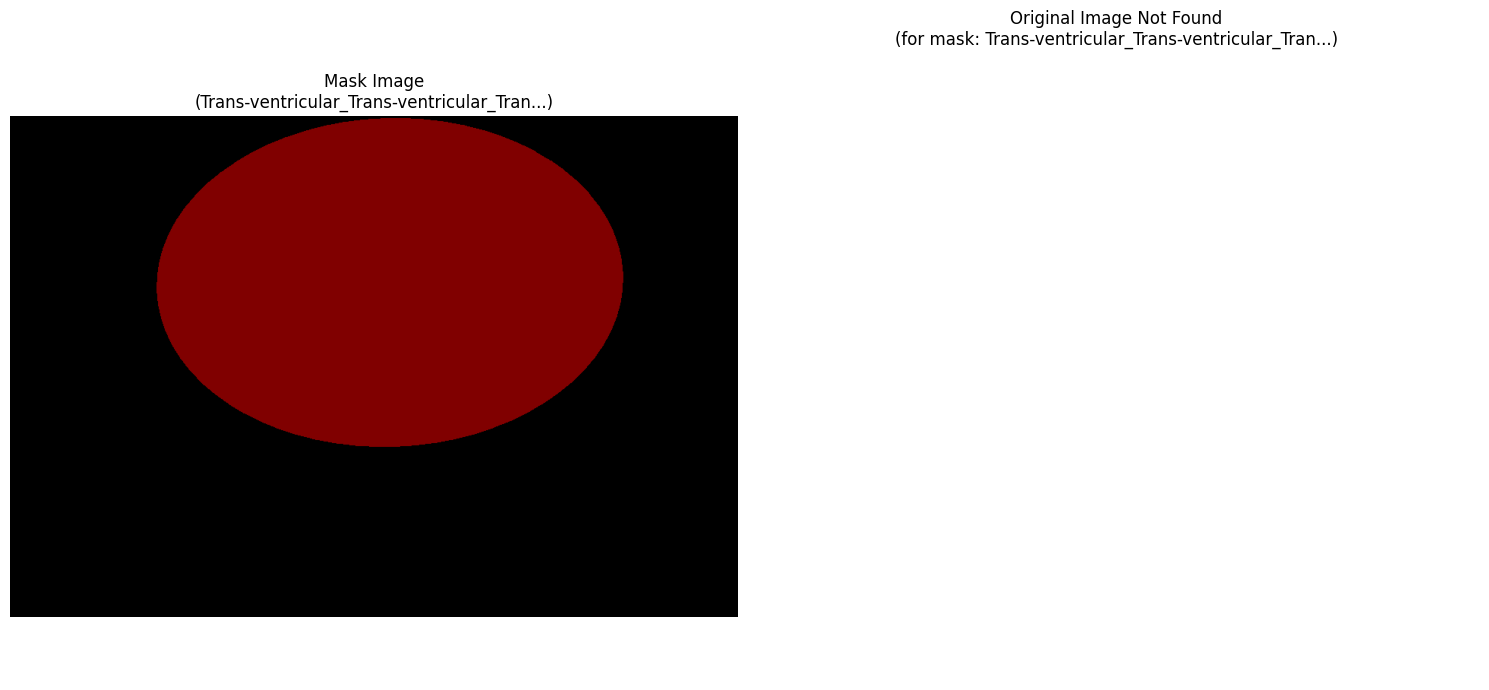


Processing mask: Trans-thalamic_Trans-thalamic_Trans-thalamic-PASCAL_SegmentationClass_Patient01177_Plane3_4_of_5.png
  Searching for original image for derived base names (case-insensitive search): ['trans_thalamic_trans_thalamic_trans_thalamic_patient01177_plane3_4_of_5', 'trans-thalamic-trans-thalamic-trans-thalamic-patient01177-plane3-4-of-5']
  Could not find a matching original image for mask: Trans-thalamic_Trans-thalamic_Trans-thalamic-PASCAL_SegmentationClass_Patient01177_Plane3_4_of_5.png


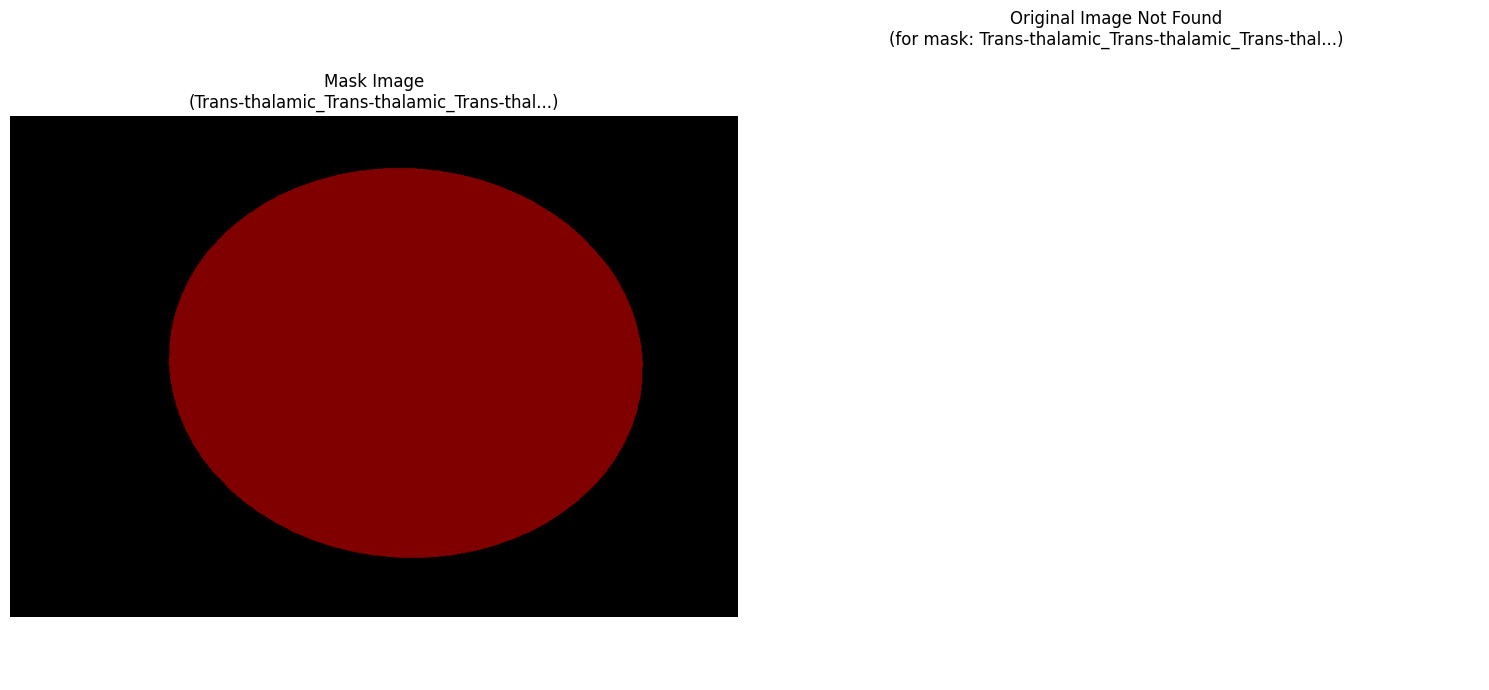


Processing mask: Diverse Fetal Head Images_Diverse Fetal Head Images_Test-Dataset-PASCAL_SegmentationClass_593_HC.png
  Searching for original image for derived base names (case-insensitive search): ['diverse_fetal_head_images_diverse_fetal_head_images_593_hc', 'diverse-fetal-head-images-diverse-fetal-head-images-593-hc']
  Could not find a matching original image for mask: Diverse Fetal Head Images_Diverse Fetal Head Images_Test-Dataset-PASCAL_SegmentationClass_593_HC.png


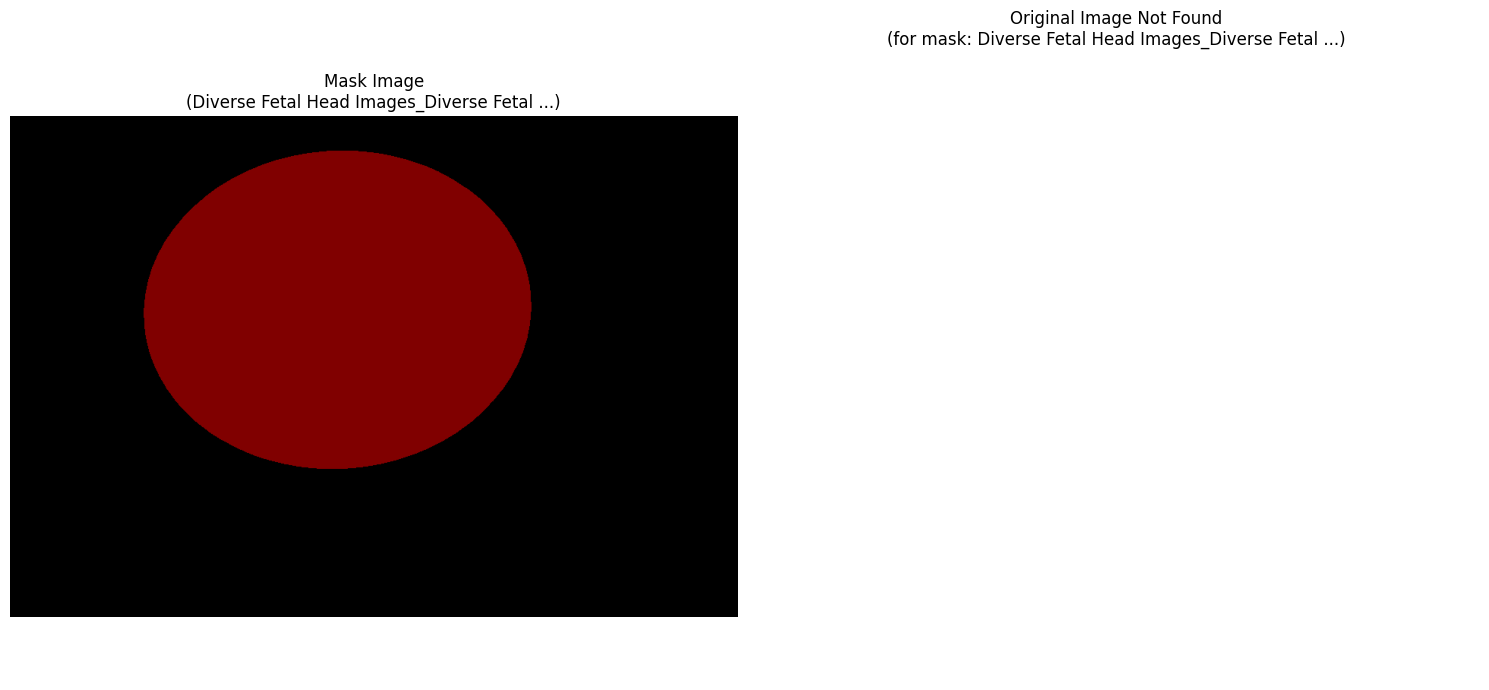

In [ ]:
import os
import random
import matplotlib.pyplot as plt
from PIL import Image
import re # Import regex module for advanced string cleaning

# Ensure FINAL_IMAGES_DIR is defined
FINAL_IMAGES_DIR = '/content/dataset_images'
segmentation_dir = os.path.join(FINAL_IMAGES_DIR, 'Segmentation')

# Get a list of all image files (which are masks) in the Segmentation folder
mask_files = [f for f in os.listdir(segmentation_dir) if f.lower().endswith(('.png', '.jpg', '.jpeg', '.bmp'))]

if not mask_files:
    print(f"No mask images found in '{segmentation_dir}'. Cannot proceed.")
else:
    print(f"Attempting to display image-mask pairs for a sample of {min(5, len(mask_files))} images.")

    # Limit the number of pairs to display to avoid overwhelming output
    display_limit = 5
    displayed_count = 0

    # Randomly select a few mask files to demonstrate the process
    sample_mask_files = random.sample(mask_files, min(display_limit, len(mask_files)))

    for selected_mask_name in sample_mask_files:
        if displayed_count >= display_limit:
            break

        selected_mask_path = os.path.join(segmentation_dir, selected_mask_name)
        print(f"\nProcessing mask: {selected_mask_name}")

        # --- Infer potential original image filename ---
        # Common mask indicators to remove from the filename
        mask_indicators = [
            # Longest, most specific full patterns first
            '-Test-Dataset-Segmentation_SegmentationClass', # From trace 3
            '-Test-Dataset-PASCAL_SegmentationClass',
            '-PASCAL-VOC _SegmentationObject',
            '-PASCAL-VOC _SegmentationClass',
            '-Open-Images_masks_default',
            '-PASCAL_SegmentationClass',
            '-Segmentation_SegmentationObject',
            '-Segmentation_SegmentationClass', # From trace 2
            '-segmentation-mask_SegmentationClass', # From trace 1

            # Composite patterns (longer specific suffixes)
            '_segmentation-mask_SegmentationClass',
            '_Segmentation_SegmentationClass',
            '_PASCAL_SegmentationObject',
            '_SegmentationObject',
            '_PASCAL_SegmentationClass',
            '_SegmentationClass',
            '_brain_00000000',
            'Open-Images_masks',
            'Test-Dataset-Segmentation', # To catch if not part of the full string above

            # Keywords that might appear as standalone words or hyphenated parts, but are part of mask ID
            'TFRecord',
            'PASCAL-VOC',
            'COCO',
            'YOLO-1.1',
            'gtFine',
            'LabelMe',
            'ICDAR-Localization',
            # 'Segmentation', # Removed as it's too broad and can be part of actual image name
            'Datumaro',
            'OpenImage',
            'Cityscapes',
            'YOLO',
            'CVAT',
            'PASCAL',
            'Test-Dataset', # Keep as it can be standalone like 'Test-Dataset-Image.png'
            '-Segmentation', # Specific to catch '-Segmentation' when not part of a longer combo

            # Generic short suffixes/words
            '_mask',
            '_masks',
            '_segmentation',
            '_label',
            '_seg',
            '_default',
            '_Object',
            '_Class',
            '_orginal_size',
            '_original_image',
            '_orig'
        ]

        # Sort indicators by length in descending order to handle longer, more specific patterns first
        mask_indicators.sort(key=len, reverse=True)

        base_name_without_ext = os.path.splitext(selected_mask_name)[0]
        # Convert to lower case for robust replacement and search
        temp_original_image_base_name = base_name_without_ext.lower()

        for indicator in mask_indicators:
            # Replace indicator with a space to help with later normalization
            temp_original_image_base_name = temp_original_image_base_name.replace(indicator.lower(), ' ')

        # Normalize spaces: replace multiple non-alphanumeric characters with a single space
        # and strip leading/trailing spaces
        base_name_with_spaces = re.sub(r'[^a-z0-9]+', ' ', temp_original_image_base_name).strip()

        # Generate multiple possible base names with different delimiters
        possible_original_image_base_names = [
            base_name_with_spaces.replace(' ', '_'), # All underscores
            base_name_with_spaces.replace(' ', '-')  # All hyphens
        ]
        # Removed problematic mixed delimiter attempts that led to malformed names
        # if '_' in base_name_without_ext.lower().replace(indicator.lower(), ' '): # Check if there were original underscores
        #     possible_original_image_base_names.append(re.sub(r' +', '_', temp_original_image_base_name).strip())
        # if '-' in base_name_without_ext.lower().replace(indicator.lower(), ' '): # Check if there were original hyphens
        #     possible_original_image_base_names.append(re.sub(r' +', '-', temp_original_image_base_name).strip())

        # Remove duplicates and add extensions
        unique_base_names = list(set(possible_original_image_base_names))

        possible_original_image_names = []
        for base_name in unique_base_names:
            possible_original_image_names.extend([
                base_name + '.png',
                base_name + '.jpg',
                base_name + '.jpeg',
                base_name + '.bmp'
            ])

        found_original_image_path = None
        print(f"  Searching for original image for derived base names (case-insensitive search): {unique_base_names}")

        for root, _, files in os.walk(FINAL_IMAGES_DIR):
            for file in files:
                # Compare against lowercased file names for robustness
                if file.lower() in possible_original_image_names:
                    found_original_image_path = os.path.join(root, file)
                    break
            if found_original_image_path:
                break

        # --- Display images ---
        plt.figure(figsize=(15, 7))

        # Display the mask image
        plt.subplot(1, 2, 1)
        try:
            mask_img = Image.open(selected_mask_path)
            plt.imshow(mask_img)
            plt.title(f"Mask Image\n({selected_mask_name[:40]}...)")
            plt.axis('off')
        except Exception as e:
            plt.title(f"Error loading mask: {e}")
            plt.axis('off')
            print(f"  Error loading mask {selected_mask_name}: {e}")

        # Display the original image if found
        plt.subplot(1, 2, 2)
        if found_original_image_path:
            try:
                original_img = Image.open(found_original_image_path)
                plt.imshow(original_img)
                plt.title(f"Original Image\n({os.path.basename(found_original_image_path)[:40]}...)")
                plt.axis('off')
                print(f"  Found original image: {os.path.basename(found_original_image_path)} in {os.path.dirname(found_original_image_path)}")
            except Exception as e:
                plt.title(f"Error loading original image: {e}")
                plt.axis('off')
                print(f"  Error loading original image {os.path.basename(found_original_image_path)}: {e}")
        else:
            # Removed Telugu characters that caused UserWarning in matplotlib
            plt.title(f"Original Image Not Found\n(for mask: {selected_mask_name[:40]}...)")
            plt.axis('off')
            print(f"  Could not find a matching original image for mask: {selected_mask_name}")

        plt.tight_layout()
        plt.show()
        displayed_count += 1

In [ ]:
import os
import random
import re

# Ensure FINAL_IMAGES_DIR is defined
FINAL_IMAGES_DIR = '/content/dataset_images'
segmentation_dir = os.path.join(FINAL_IMAGES_DIR, 'Segmentation')

# Get a list of all image files (which are masks) in the Segmentation folder
mask_files = [f for f in os.listdir(segmentation_dir) if f.lower().endswith(('.png', '.jpg', '.jpeg', '.bmp'))]

if not mask_files:
    print(f"No mask images found in '{segmentation_dir}'. Cannot proceed with verification.")
else:
    print(f"Verifying mask-to-image matching for a sample of {min(20, len(mask_files))} masks.")

    # Select a sample of masks for verification
    sample_size = min(20, len(mask_files))
    sample_mask_files = random.sample(mask_files, sample_size)

    # Re-define mask_indicators (should be consistent with previous cell)
    mask_indicators = [
        '-Test-Dataset-Segmentation_SegmentationClass',
        '-Test-Dataset-PASCAL_SegmentationClass',
        '-PASCAL-VOC _SegmentationObject',
        '-PASCAL-VOC _SegmentationClass',
        '-Open-Images_masks_default',
        '-PASCAL_SegmentationClass',
        '-Segmentation_SegmentationObject',
        '-Segmentation_SegmentationClass',
        '-segmentation-mask_SegmentationClass',
        '_segmentation-mask_SegmentationClass',
        '_Segmentation_SegmentationClass',
        '_PASCAL_SegmentationObject',
        '_SegmentationObject',
        '_PASCAL_SegmentationClass',
        '_SegmentationClass',
        '_brain_00000000',
        'Open-Images_masks',
        'Test-Dataset-Segmentation',
        'TFRecord',
        'PASCAL-VOC',
        'COCO',
        'YOLO-1.1',
        'gtFine',
        'LabelMe',
        'ICDAR-Localization',
        'Datumaro',
        'OpenImage',
        'Cityscapes',
        'YOLO',
        'CVAT',
        'PASCAL',
        'Test-Dataset',
        '-Segmentation',
        '_mask',
        '_masks',
        '_segmentation',
        '_label',
        '_seg',
        '_default',
        '_Object',
        '_Class',
        '_orginal_size',
        '_original_image',
        '_orig'
    ]
    mask_indicators.sort(key=len, reverse=True)

    found_pairs_count = 0
    for i, selected_mask_name in enumerate(sample_mask_files):
        base_name_without_ext = os.path.splitext(selected_mask_name)[0]
        temp_original_image_base_name = base_name_without_ext.lower()

        for indicator in mask_indicators:
            temp_original_image_base_name = temp_original_image_base_name.replace(indicator.lower(), ' ')

        base_name_with_spaces = re.sub(r'[^a-z0-9]+', ' ', temp_original_image_base_name).strip()

        possible_original_image_base_names = [
            base_name_with_spaces.replace(' ', '_'), # All underscores
            base_name_with_spaces.replace(' ', '-')  # All hyphens
        ]
        # Removed problematic mixed delimiter attempts that led to malformed names
        # if '_' in base_name_without_ext.lower().replace(indicator.lower(), ' '): # Check if there were original underscores
        #     possible_original_image_base_names.append(re.sub(r' +', '_', temp_original_image_base_name).strip())
        # if '-' in base_name_without_ext.lower().replace(indicator.lower(), ' '): # Check if there were original hyphens
        #     possible_original_image_base_names.append(re.sub(r' +', '-', temp_original_image_base_name).strip())

        unique_base_names = list(set(possible_original_image_base_names))

        possible_original_image_names_with_ext = []
        for base_name in unique_base_names:
            possible_original_image_names_with_ext.extend([
                base_name + '.png',
                base_name + '.jpg',
                base_name + '.jpeg',
                base_name + '.bmp'
            ])

        found_original_image_path = None
        for root, _, files in os.walk(FINAL_IMAGES_DIR):
            for file in files:
                if file.lower() in possible_original_image_names_with_ext:
                    found_original_image_path = os.path.join(root, file)
                    break
            if found_original_image_path:
                break

        status = "FOUND" if found_original_image_path else "NOT FOUND"
        if found_original_image_path: found_pairs_count += 1
        print(f"\n{i+1}. Mask: {selected_mask_name}")
        print(f"   Derived Original Base Names Attempted: {unique_base_names}")
        print(f"   Original Image Status: {status}")
        if found_original_image_path:
            print(f"   Path: {found_original_image_path}")

    print(f"\n--- Verification Summary ---")
    print(f"Total masks in sample: {sample_size}")
    print(f"Original images found: {found_pairs_count}")
    print(f"Original images not found: {sample_size - found_pairs_count}")

Verifying mask-to-image matching for a sample of 20 masks.

1. Mask: Diverse Fetal Head Images_Diverse Fetal Head Images_Test-Dataset-PASCAL_SegmentationClass_399_2HC.png
   Derived Original Base Names Attempted: ['diverse_fetal_head_images_diverse_fetal_head_images_399_2hc', 'diverse-fetal-head-images-diverse-fetal-head-images-399-2hc']
   Original Image Status: NOT FOUND

2. Mask: Trans-cerebellum_Trans-cerebellum_Trans-cerebellum-Segmentation_SegmentationClass_Patient00967_Plane3_2_of_5.png
   Derived Original Base Names Attempted: ['trans-cerebellum-trans-cerebellum-trans-cerebellum-patient00967-plane3-2-of-5', 'trans_cerebellum_trans_cerebellum_trans_cerebellum_patient00967_plane3_2_of_5']
   Original Image Status: NOT FOUND

3. Mask: Diverse Fetal Head Images_Diverse Fetal Head Images_Test-Dataset-PASCAL_SegmentationClass_376_HC.png
   Derived Original Base Names Attempted: ['diverse_fetal_head_images_diverse_fetal_head_images_376_hc', 'diverse-fetal-head-images-diverse-fetal-hea

In [ ]:
import os
import random

FINAL_IMAGES_DIR = '/content/dataset_images'

print(f"Listing sample filenames from subfolders in '{FINAL_IMAGES_DIR}':\n")

# Get a list of all subdirectories within FINAL_IMAGES_DIR
subdirectories = [d for d in os.listdir(FINAL_IMAGES_DIR) if os.path.isdir(os.path.join(FINAL_IMAGES_DIR, d))]

for subdir_name in sorted(subdirectories):
    subdir_path = os.path.join(FINAL_IMAGES_DIR, subdir_name)
    image_files = [f for f in os.listdir(subdir_path) if f.lower().endswith(('.png', '.jpg', '.jpeg', '.bmp'))]

    if not image_files:
        print(f"--- No image files found in '{subdir_name}' (Total: 0 files) ---")
    else:
        sample_size = min(5, len(image_files)) # Display up to 5 random filenames
        random_sample = random.sample(image_files, sample_size)

        print(f"--- '{subdir_name}' (Total: {len(image_files)} files) ---")
        for filename in random_sample:
            print(f"  - {filename}")
        if len(image_files) > sample_size:
            print(f"  ... {len(image_files) - sample_size} more files ...")
        print()

Listing sample filenames from subfolders in '/content/dataset_images':

--- 'LabelMe' (Total: 3792 files) ---
  - Diverse Fetal Head Images_Diverse Fetal Head Images_Test-Dataset-LabelMe_default_Masks_047_HC_mask_0.png
  - Diverse Fetal Head Images_Diverse Fetal Head Images_Test-Dataset-LabelMe_default_Masks_469_2HC_mask_0.png
  - Trans-thalamic_Trans-thalamic_Trans-thalamic-LabelMe_default_Masks_Patient00659_Plane3_1_of_1_mask_0.png
  - Trans-thalamic_Trans-thalamic_Trans-thalamic-LabelMe_default_Masks_Patient00990_Plane3_2_of_3_mask_0.png
  - Trans-thalamic_Trans-thalamic_Trans-thalamic-LabelMe_default_Masks_Patient00892_Plane3_1_of_3_mask_1.png
  ... 3787 more files ...

--- 'OpenImage' (Total: 5300 files) ---
  - Diverse Fetal Head Images_Diverse Fetal Head Images_Test-Dataset-OpenImage_masks_default_527_hc_lv_00000002.png
  - Trans-cerebellum_Trans-cerebellum_Trans-cerebellum-OpenImage_masks_default_patient01602_plane3_5_of_6_csp_00000001.png
  - Diverse Fetal Head Images_Diverse 

In [ ]:
import os
import shutil

# Define the new directory for all masks
ALL_MASKS_DIR = '/content/all_masks'
os.makedirs(ALL_MASKS_DIR, exist_ok=True)
print(f"Created directory for all masks: {ALL_MASKS_DIR}")

# List of subdirectories within FINAL_IMAGES_DIR that are considered mask/annotation folders
mask_subdirs_to_consolidate = ['LabelMe', 'OpenImage', 'Segmentation', 'gtFine']

moved_files_count = 0
moved_categories = {}

print(f"\nMoving files from: {mask_subdirs_to_consolidate} to {ALL_MASKS_DIR}\n")

for subdir_name in mask_subdirs_to_consolidate:
    source_subdir_path = os.path.join(FINAL_IMAGES_DIR, subdir_name)

    if os.path.exists(source_subdir_path) and os.path.isdir(source_subdir_path):
        files_in_subdir = [f for f in os.listdir(source_subdir_path) if os.path.isfile(os.path.join(source_subdir_path, f))]

        if files_in_subdir:
            print(f"Processing '{subdir_name}' with {len(files_in_subdir)} files...")
            for filename in files_in_subdir:
                source_file_path = os.path.join(source_subdir_path, filename)
                destination_file_path = os.path.join(ALL_MASKS_DIR, filename)

                # Handle potential filename collisions by renaming if necessary
                # For simplicity, we assume unique filenames across categories for now due to flattening earlier
                # If collisions are expected, add logic here (e.g., append counter or use original subdir as prefix)

                shutil.move(source_file_path, destination_file_path)
                moved_files_count += 1
            moved_categories[subdir_name] = len(files_in_subdir)
            shutil.rmtree(source_subdir_path) # Remove the now-empty subdirectory
            print(f"  Removed empty directory: {source_subdir_path}")
        else:
            print(f"'{subdir_name}' is empty. Skipping.")
    else:
        print(f"Directory '{source_subdir_path}' does not exist. Skipping.")

print(f"\nConsolidation complete!")
print(f"Total files moved to '{ALL_MASKS_DIR}': {moved_files_count}")
print("Details:")
for category, count in moved_categories.items():
    print(f"  - From '{category}': {count} files")

print(f"\nVerifying contents of '{FINAL_IMAGES_DIR}':")
remaining_items = os.listdir(FINAL_IMAGES_DIR)
if remaining_items:
    print(f"  Remaining items: {remaining_items}")
else:
    print("  'FINAL_IMAGES_DIR' is now empty (except for 'Uncategorized' if it existed and was skipped).")

# If 'Uncategorized' was meant to be the ONLY remaining folder, re-check
uncategorized_path = os.path.join(FINAL_IMAGES_DIR, 'Uncategorized')
if os.path.exists(uncategorized_path) and os.path.isdir(uncategorized_path):
    print(f"  'Uncategorized' directory is still present with {len(os.listdir(uncategorized_path))} files.")


Created directory for all masks: /content/all_masks

Moving files from: ['LabelMe', 'OpenImage', 'Segmentation', 'gtFine'] to /content/all_masks

Processing 'LabelMe' with 3792 files...
  Removed empty directory: /content/dataset_images/LabelMe
Processing 'OpenImage' with 5300 files...
  Removed empty directory: /content/dataset_images/OpenImage
Processing 'Segmentation' with 16527 files...
  Removed empty directory: /content/dataset_images/Segmentation
Processing 'gtFine' with 11496 files...
  Removed empty directory: /content/dataset_images/gtFine

Consolidation complete!
Total files moved to '/content/all_masks': 37115
Details:
  - From 'LabelMe': 3792 files
  - From 'OpenImage': 5300 files
  - From 'Segmentation': 16527 files
  - From 'gtFine': 11496 files

Verifying contents of '/content/dataset_images':
  Remaining items: ['Uncategorized']
  'Uncategorized' directory is still present with 7780 files.


In [ ]:
import os
import random
import re

# Define the directory containing all masks and the directory containing original images
ALL_MASKS_DIR = '/content/all_masks'
ORIGINAL_IMAGES_DIR = os.path.join(FINAL_IMAGES_DIR, 'Uncategorized')

# Get a list of all mask files
mask_files = [f for f in os.listdir(ALL_MASKS_DIR) if f.lower().endswith(('.png', '.jpg', '.jpeg', '.bmp'))]

if not mask_files:
    print(f"No mask images found in '{ALL_MASKS_DIR}'. Cannot proceed with verification.")
elif not os.path.exists(ORIGINAL_IMAGES_DIR) or not os.listdir(ORIGINAL_IMAGES_DIR):
    print(f"No original images found in '{ORIGINAL_IMAGES_DIR}'. Cannot proceed with verification.")
else:
    print(f"Verifying mask-to-image matching for a sample of {min(50, len(mask_files))} masks.\n")

    # Select a sample of masks for verification
    sample_size = min(50, len(mask_files)) # Increase sample size for better representation
    sample_mask_files = random.sample(mask_files, sample_size)

    # Mask indicators to remove from filename to derive original image name
    mask_indicators = [
        # Longest, most specific full patterns first
        '-Test-Dataset-Segmentation_SegmentationClass',
        '-Test-Dataset-PASCAL_SegmentationClass',
        '-PASCAL-VOC _SegmentationObject',
        '-PASCAL-VOC _SegmentationClass',
        '-Open-Images_masks_default',
        '-PASCAL_SegmentationClass',
        '-Segmentation_SegmentationObject',
        '-Segmentation_SegmentationClass',
        '-segmentation-mask_SegmentationClass',
        '_segmentation-mask_SegmentationClass',
        '_Segmentation_SegmentationClass',
        '_PASCAL_SegmentationObject',
        '_SegmentationObject',
        '_PASCAL_SegmentationClass',
        '_SegmentationClass',
        '_brain_00000000',
        'Open-Images_masks',
        'Test-Dataset-Segmentation',

        # Keywords that might appear as standalone words or hyphenated parts, but are part of mask ID
        'TFRecord',
        'PASCAL-VOC',
        'COCO',
        'YOLO-1.1',
        'gtFine',
        'LabelMe',
        'ICDAR-Localization',
        'Datumaro',
        'OpenImage',
        'Cityscapes',
        'YOLO',
        'CVAT',
        'PASCAL',
        'Test-Dataset',
        '-Segmentation',

        # Generic short suffixes/words
        '_mask',
        '_masks',
        '_segmentation',
        '_label',
        '_seg',
        '_default',
        '_Object',
        '_Class',
        '_orginal_size',
        '_original_image',
        '_orig'
    ]
    mask_indicators.sort(key=len, reverse=True) # Sort by length descending for robust replacement

    found_pairs_count = 0
    for i, selected_mask_name in enumerate(sample_mask_files):
        base_name_without_ext = os.path.splitext(selected_mask_name)[0]
        temp_original_image_base_name = base_name_without_ext.lower()

        for indicator in mask_indicators:
            temp_original_image_base_name = temp_original_image_base_name.replace(indicator.lower(), ' ')

        # Clean up spaces and generate possible base names with underscores and hyphens
        base_name_with_spaces = re.sub(r'[^a-z0-9]+', ' ', temp_original_image_base_name).strip()
        possible_original_image_base_names = [
            base_name_with_spaces.replace(' ', '_'),
            base_name_with_spaces.replace(' ', '-')
        ]
        unique_base_names = list(set(possible_original_image_base_names))

        # Generate possible full filenames with extensions
        possible_original_image_names_with_ext = []
        for base_name in unique_base_names:
            possible_original_image_names_with_ext.extend([
                base_name + '.png',
                base_name + '.jpg',
                base_name + '.jpeg',
                base_name + '.bmp'
            ])

        found_original_image_path = None
        # Search for the inferred original image in the ORIGINAL_IMAGES_DIR
        for file in os.listdir(ORIGINAL_IMAGES_DIR):
            if file.lower() in possible_original_image_names_with_ext:
                found_original_image_path = os.path.join(ORIGINAL_IMAGES_DIR, file)
                break

        status = "FOUND" if found_original_image_path else "NOT FOUND"
        if found_original_image_path:
            found_pairs_count += 1

        print(f"{i+1}. Mask: {selected_mask_name}")
        print(f"   Derived Original Base Names Attempted: {unique_base_names}")
        print(f"   Original Image Status: {status}")
        if found_original_image_path:
            print(f"   Path: {found_original_image_path}")
        print()

    print(f"--- Verification Summary ---")
    print(f"Total masks in sample: {sample_size}")
    print(f"Original images found: {found_pairs_count}")
    print(f"Original images not found: {sample_size - found_pairs_count}")

Verifying mask-to-image matching for a sample of 50 masks.

1. Mask: Diverse Fetal Head Images_Diverse Fetal Head Images_Test-Dataset-PASCAL_SegmentationClass_474_HC.png
   Derived Original Base Names Attempted: ['diverse-fetal-head-images-diverse-fetal-head-images-474-hc', 'diverse_fetal_head_images_diverse_fetal_head_images_474_hc']
   Original Image Status: NOT FOUND

2. Mask: Trans-thalamic_Trans-thalamic_Trans-thalamic-OpenImage-14-3-23_masks_default_patient00697_plane3_7_of_7_brain_00000000.png
   Derived Original Base Names Attempted: ['trans_thalamic_trans_thalamic_trans_thalamic_14_3_23_patient00697_plane3_7_of_7', 'trans-thalamic-trans-thalamic-trans-thalamic-14-3-23-patient00697-plane3-7-of-7']
   Original Image Status: NOT FOUND

3. Mask: Diverse Fetal Head Images_Diverse Fetal Head Images_Test-Dataset-Segmentation_SegmentationObject_379_HC.png
   Derived Original Base Names Attempted: ['diverse-fetal-head-images-diverse-fetal-head-images-379-hc', 'diverse_fetal_head_images

In [ ]:
import os
import random

# Define the directories (already available from previous cells)
ALL_MASKS_DIR = '/content/all_masks'
ORIGINAL_IMAGES_DIR = '/content/dataset_images/Uncategorized'

# --- 1. List a random sample of 20 filenames from ALL_MASKS_DIR ---
mask_filenames = [f for f in os.listdir(ALL_MASKS_DIR) if os.path.isfile(os.path.join(ALL_MASKS_DIR, f))]

if not mask_filenames:
    print(f"No files found in {ALL_MASKS_DIR}")
else:
    sample_size = min(20, len(mask_filenames))
    random_mask_sample = random.sample(mask_filenames, sample_size)
    print(f"\n--- Random Sample of {sample_size} Filenames from ALL_MASKS_DIR ---")
    for filename in random_mask_sample:
        print(filename)

# --- 2. List a random sample of 20 filenames from ORIGINAL_IMAGES_DIR ---
original_image_filenames = [f for f in os.listdir(ORIGINAL_IMAGES_DIR) if os.path.isfile(os.path.join(ORIGINAL_IMAGES_DIR, f))]

if not original_image_filenames:
    print(f"No files found in {ORIGINAL_IMAGES_DIR}")
else:
    sample_size = min(20, len(original_image_filenames))
    random_original_sample = random.sample(original_image_filenames, sample_size)
    print(f"\n--- Random Sample of {sample_size} Filenames from ORIGINAL_IMAGES_DIR ---")
    for filename in random_original_sample:
        print(filename)



--- Random Sample of 20 Filenames from ALL_MASKS_DIR ---
Trans-cerebellum_Trans-cerebellum_Trans-cerebellum-PASCAL_SegmentationClass_Patient00798_Plane3_1_of_2.png
Diverse Fetal Head Images_Diverse Fetal Head Images_Test-Dataset-LabelMe_default_Masks_607_HC_mask_0.png
Trans-thalamic_Trans-thalamic_Trans-thalamic-OpenImage-14-3-23_masks_default_patient01316_plane3_1_of_3_lv_00000001.png
Trans-ventricular_Trans-ventricular_Trans-ventricular-CityScapes_gtFine_default_Patient00961_Plane3_2_of_4_gtFine_labelIds.png
Trans-thalamic_Trans-thalamic_Trans-thalamic-Segmentation_SegmentationObject_Patient01771_Plane3_3_of_4.png
Diverse Fetal Head Images_Diverse Fetal Head Images_Test-Dataset-Segmentation_SegmentationObject_001_HC.png
Diverse Fetal Head Images_Diverse Fetal Head Images_Test-Dataset-CitySpaces_gtFine_default_057_HC_gtFine_color.png
Trans-thalamic_Trans-thalamic_Trans-thalamic-Cityscapes_gtFine_default_Patient01243_Plane3_1_of_1_gtFine_labelIds.png
Trans-cerebellum_Trans-cerebellum_

In [ ]:
import os
import re

# Existing FINAL_IMAGES_DIR and ALL_MASKS_DIR are defined in previous cells
# Assuming ALL_MASKS_DIR = '/content/all_masks'
# Assuming ORIGINAL_IMAGES_DIR = '/content/dataset_images/Uncategorized'

# --- Refined mask_indicators list ---
# Prioritize longest and most specific patterns first for accurate removal
mask_indicators = [
    '-PASCAL-VOC _SegmentationClass', # Specific PASCAL-VOC pattern with space
    '-PASCAL-VOC _SegmentationObject',
    '-Test-Dataset-Segmentation_SegmentationClass',
    '-Test-Dataset-PASCAL_SegmentationClass',
    '-Open-Images_masks_default',
    '-Segmentation_SegmentationObject',
    '-Segmentation_SegmentationClass',
    '-segmentation-mask_SegmentationClass',
    '-Cityscapes_gtFine_default',
    '-PASCAL_SegmentationClass',
    '-PASCAL_SegmentationObject',

    # More general dataset/format indicators (longer ones first)
    'gtFine_labelIds',
    'gtFine_instanceIds',
    'gtFine_color',
    'gtFine_polygons',
    'gtFine',
    'LabelMe_default_Masks',
    'OpenImage_masks_default',
    'OpenImage-14-3-23_masks_default',
    'Test-Dataset-CitySpaces',
    'Test-Dataset-LabelMe',
    'Test-Dataset-PASCAL',
    'Test-Dataset-Segmentation',
    'TFRecord',
    'PASCAL-VOC',
    'COCO',
    'YOLO-1.1',
    'ICDAR-Localization',
    'Datumaro',
    'Cityscapes',
    'CVAT',
    'OpenImage',
    'PASCAL',
    'YOLO',

    # Common mask-specific suffixes/identifiers (longer ones first)
    '_mask_0',
    '_mask_1',
    '_mask_2',
    '_mask_3',
    '_mask_4',
    '_brain_00000000',
    '_csp_00000001',
    '_lv_00000001',
    '_segmentation_mask',
    '_SegmentationObject',
    '_SegmentationClass',
    '_annotation',
    '_labelIds',
    '_instanceIds',
    '_color',
    '_default',
    '_mask',
    '_masks',
    '_segmentation',
    '_label',
    '_seg',
    '_Object',
    '_Class',

    # Original image indicators that might appear in masks if not cleaned
    '_orginal-image',
    '_orginal-size',
    '_Orginal_train_images_to_959_661',

    # General clean-up terms
    '_orig',
    '_HC',
    '_2HC',
    '_4HC',
    '_6HC',
    '_8HC',

    # Numeric suffixes often indicating mask index/type that should be removed
    # Be careful not to remove patient/plane numbers unless certain
    # For now, targeting very specific patterns like mask indices
    '_00000000',
    '_00000001',
    '_00000002',
    '_00000003',
    '_00000004',
    '_00000005',

]

# Sort indicators by length in descending order to ensure longer, more specific patterns are replaced first.
mask_indicators.sort(key=len, reverse=True)

# --- Example of improved stripping logic ---
# Get a sample mask filename (using one from the previous output for consistency)
sample_mask_name = "Trans-cerebellum_Trans-cerebellum_Trans-cerebellum-PASCAL_SegmentationObject_Patient01298_Plane3_2_of_9.png"

base_name_without_ext = os.path.splitext(sample_mask_name)[0]
processed_name = base_name_without_ext.lower()

print(f"Original Mask Name: {sample_mask_name}")
print(f"Initial lowercase base name: {processed_name}")

for indicator in mask_indicators:
    # Replace indicator (case-insensitive) with a space to help with later normalization
    if indicator.lower() in processed_name:
        processed_name = processed_name.replace(indicator.lower(), ' ')

# Clean up any residual non-alphanumeric characters (except valid delimiters) and multiple spaces
# Also, preserve original underscores/hyphens where they likely acted as separators
# First, consolidate multiple spaces into one, then strip leading/trailing spaces
processed_name = re.sub(r'\s+', ' ', processed_name).strip()

# Now, convert spaces back to underscores, which is a common delimiter in original names
final_derived_name = processed_name.replace(' ', '_')

# Remove any consecutive underscores or hyphens that might have resulted from stripping
final_derived_name = re.sub(r'[_]+', '_', final_derived_name)
final_derived_name = re.sub(r'[-]+', '-', final_derived_name)

# Trim leading/trailing delimiters
final_derived_name = final_derived_name.strip('_-')

print(f"Derived Original Image Base Name: {final_derived_name}")

print("\n--- Refined mask_indicators list (sorted by length) ---")
for ind in mask_indicators:
    print(f"- {ind}")

print("\n--- Explanation of Updated Logic ---")
print("1. The `mask_indicators` list has been expanded with more specific patterns observed in mask filenames, including dataset-specific tags (e.g., `gtFine_labelIds`, `Test-Dataset-Segmentation`), annotation types (`_SegmentationObject`, `_mask_0`), and common suffixes like `_HC`, `_brain_00000000`.")
print("2. The list is sorted by length in descending order. This ensures that longer, more specific patterns (e.g., `-Test-Dataset-Segmentation_SegmentationClass`) are replaced before shorter, more general components (e.g., `Segmentation` or `Test-Dataset`) are accidentally removed, preventing partial matches and improving accuracy.")
print("3. The stripping process now converts the filename to lowercase for consistent, case-insensitive matching and replacement.")
print("4. After replacing indicators with spaces, `re.sub(r'\\s+', ' ', processed_name).strip()` is used to consolidate multiple spaces into single spaces and remove leading/trailing spaces.")
print("5. `final_derived_name = processed_name.replace(' ', '_')` converts remaining spaces to underscores, which is a common delimiter in original filenames.")
print("6. `re.sub(r'[_]+', '_', final_derived_name)` and `re.sub(r'[-]+', '-', final_derived_name)` are applied to remove any consecutive underscores or hyphens that might have resulted from the replacements, ensuring clean delimiters.")
print("7. Finally, `strip('_-')` removes any leading or trailing underscores or hyphens from the derived name, ensuring a clean base identifier for the original image.")


Original Mask Name: Trans-cerebellum_Trans-cerebellum_Trans-cerebellum-PASCAL_SegmentationObject_Patient01298_Plane3_2_of_9.png
Initial lowercase base name: trans-cerebellum_trans-cerebellum_trans-cerebellum-pascal_segmentationobject_patient01298_plane3_2_of_9
Derived Original Image Base Name: trans-cerebellum_trans-cerebellum_trans-cerebellum_patient01298_plane3_2_of_9

--- Refined mask_indicators list (sorted by length) ---
- -Test-Dataset-Segmentation_SegmentationClass
- -Test-Dataset-PASCAL_SegmentationClass
- -segmentation-mask_SegmentationClass
- -Segmentation_SegmentationObject
- _Orginal_train_images_to_959_661
- -PASCAL-VOC _SegmentationObject
- -Segmentation_SegmentationClass
- OpenImage-14-3-23_masks_default
- -PASCAL-VOC _SegmentationClass
- -Open-Images_masks_default
- -Cityscapes_gtFine_default
- -PASCAL_SegmentationObject
- -PASCAL_SegmentationClass
- Test-Dataset-Segmentation
- OpenImage_masks_default
- Test-Dataset-CitySpaces
- LabelMe_default_Masks
- Test-Dataset-Labe

In [ ]:
import os
import re
import random

# Ensure ALL_MASKS_DIR and ORIGINAL_IMAGES_DIR are defined from previous cells
# Assuming ALL_MASKS_DIR = '/content/all_masks'
# Assuming ORIGINAL_IMAGES_DIR = '/content/dataset_images/Uncategorized'

# Refined mask_indicators list (copied from previous successful run)
mask_indicators = [
    '-PASCAL-VOC _SegmentationClass', # Specific PASCAL-VOC pattern with space
    '-PASCAL-VOC _SegmentationObject',
    '-Test-Dataset-Segmentation_SegmentationClass',
    '-Test-Dataset-PASCAL_SegmentationClass',
    '-Open-Images_masks_default',
    '-Segmentation_SegmentationObject',
    '-Segmentation_SegmentationClass',
    '-segmentation-mask_SegmentationClass',
    '-Cityscapes_gtFine_default',
    '-PASCAL_SegmentationClass',
    '-PASCAL_SegmentationObject',

    # More general dataset/format indicators (longer ones first)
    'gtFine_labelIds',
    'gtFine_instanceIds',
    'gtFine_color',
    'gtFine_polygons',
    'gtFine',
    'LabelMe_default_Masks',
    'OpenImage_masks_default',
    'OpenImage-14-3-23_masks_default',
    'Test-Dataset-CitySpaces',
    'Test-Dataset-LabelMe',
    'Test-Dataset-PASCAL',
    'Test-Dataset-Segmentation',
    'TFRecord',
    'PASCAL-VOC',
    'COCO',
    'YOLO-1.1',
    'ICDAR-Localization',
    'Datumaro',
    'Cityscapes',
    'CVAT',
    'OpenImage',
    'PASCAL',
    'YOLO',

    # Common mask-specific suffixes/identifiers (longer ones first)
    '_mask_0',
    '_mask_1',
    '_mask_2',
    '_mask_3',
    '_mask_4',
    '_brain_00000000',
    '_csp_00000001',
    '_lv_00000001',
    '_segmentation_mask',
    '_SegmentationObject',
    '_SegmentationClass',
    '_annotation',
    '_labelIds',
    '_instanceIds',
    '_color',
    '_default',
    '_mask',
    '_masks',
    '_segmentation',
    '_label',
    '_seg',
    '_Object',
    '_Class',

    # Original image indicators that might appear in masks if not cleaned
    '_orginal-image',
    '_orginal-size',
    '_Orginal_train_images_to_959_661',

    # General clean-up terms
    '_orig',
    '_HC',
    '_2HC',
    '_4HC',
    '_6HC',
    '_8HC',

    # Numeric suffixes often indicating mask index/type that should be removed
    # Be careful not to remove patient/plane numbers unless certain
    # For now, targeting very specific patterns like mask indices
    '_00000000',
    '_00000001',
    '_00000002',
    '_00000003',
    '_00000004',
    '_00000005',
]

# Sort indicators by length in descending order to ensure longest, most specific patterns are replaced first.
mask_indicators.sort(key=len, reverse=True)

def find_original_image(mask_filename, original_images_dir, mask_indicators=mask_indicators):
    """
    Derives possible original image filenames from a mask filename and searches for them.

    Args:
        mask_filename (str): The filename of the mask image.
        original_images_dir (str): The directory containing potential original images.
        mask_indicators (list): A sorted list of strings to strip from the mask filename.

    Returns:
        str: The full path to the original image if found, otherwise None.
    """
    base_name_without_ext = os.path.splitext(mask_filename)[0]
    processed_name = base_name_without_ext.lower()

    for indicator in mask_indicators:
        if indicator.lower() in processed_name:
            processed_name = processed_name.replace(indicator.lower(), ' ')

    processed_name = re.sub(r'\s+', ' ', processed_name).strip()

    # Generate possible base names with underscores and hyphens
    possible_original_image_base_names = [
        processed_name.replace(' ', '_'),  # All underscores
        processed_name.replace(' ', '-')   # All hyphens
    ]

    # Add a version with no delimiters if that's a pattern
    if len(processed_name.replace(' ', '')) > 0:
      possible_original_image_base_names.append(processed_name.replace(' ', ''))

    unique_base_names = list(set(possible_original_image_base_names))

    # Generate possible full filenames with extensions for case-insensitive matching
    possible_original_image_names_with_ext_lower = []
    for base_name in unique_base_names:
        # Clean up consecutive delimiters that might have been formed
        clean_base_name = re.sub(r'[_]+', '_', base_name)
        clean_base_name = re.sub(r'[-]+', '-', clean_base_name)
        clean_base_name = clean_base_name.strip('_-') # Trim leading/trailing delimiters

        if not clean_base_name: # Skip empty base names after stripping
            continue

        possible_original_image_names_with_ext_lower.extend([
            clean_base_name + '.png',
            clean_base_name + '.jpg',
            clean_base_name + '.jpeg',
            clean_base_name + '.bmp'
        ])

    # Get all original image filenames (lowercased for efficient lookup)
    original_image_filenames_lower = {f.lower(): f for f in os.listdir(original_images_dir) if os.path.isfile(os.path.join(original_images_dir, f))}

    for derived_name_lower in possible_original_image_names_with_ext_lower:
        if derived_name_lower in original_image_filenames_lower:
            # Return the original case filename if found
            return os.path.join(original_images_dir, original_image_filenames_lower[derived_name_lower])

    return None

# --- Test the function with sample mask filenames ---
print("Testing find_original_image function with sample masks...")

all_masks = [f for f in os.listdir(ALL_MASKS_DIR) if os.path.isfile(os.path.join(ALL_MASKS_DIR, f))]

if not all_masks:
    print(f"No mask files found in {ALL_MASKS_DIR}. Cannot test function.")
else:
    sample_masks_to_test = random.sample(all_masks, min(10, len(all_masks))) # Test with 10 random masks

    for mask_name in sample_masks_to_test:
        original_path = find_original_image(mask_name, ORIGINAL_IMAGES_DIR)
        if original_path:
            print(f"Mask: {mask_name}\n  -> Original Image Found: {os.path.basename(original_path)}\n")
        else:
            print(f"Mask: {mask_name}\n  -> Original Image NOT Found.\n")



Testing find_original_image function with sample masks...
Mask: Trans-ventricular_Trans-ventricular_Trans-ventricular-CityScapes_gtFine_default_Patient01761_Plane3_2_of_2_gtFine_color.png
  -> Original Image Found: Trans-ventricular_Trans-ventricular_Trans-ventricular_Patient01761_Plane3_2_of_2.png

Mask: Diverse Fetal Head Images_Diverse Fetal Head Images_Test-Dataset-PASCAL_SegmentationClass_035_HC.png
  -> Original Image NOT Found.

Mask: Trans-thalamic_Trans-thalamic_Trans-thalamic-PASCAL_SegmentationObject_Patient01536_Plane3_3_of_3.png
  -> Original Image Found: Trans-thalamic_Trans-thalamic_Trans-thalamic_Patient01536_Plane3_3_of_3.png

Mask: Trans-thalamic_Trans-thalamic_Trans-thalamic-Cityscapes_gtFine_default_Patient00975_Plane3_3_of_3_gtFine_labelIds.png
  -> Original Image Found: Trans-thalamic_Trans-thalamic_Trans-thalamic_Patient00975_Plane3_3_of_3.png

Mask: Trans-ventricular_Trans-ventricular_Trans-ventricular-segmentation-mask_SegmentationObject_Patient01130_Plane3_1_o

In [ ]:
import os

# Ensure ALL_MASKS_DIR and ORIGINAL_IMAGES_DIR are defined
ALL_MASKS_DIR = '/content/all_masks'
ORIGINAL_IMAGES_DIR = '/content/dataset_images/Uncategorized'

# Get a list of all mask filenames from ALL_MASKS_DIR
all_mask_filenames = [f for f in os.listdir(ALL_MASKS_DIR) if os.path.isfile(os.path.join(ALL_MASKS_DIR, f))]

if not all_mask_filenames:
    print(f"No mask files found in '{ALL_MASKS_DIR}'. Skipping evaluation.")
elif not os.path.exists(ORIGINAL_IMAGES_DIR) or not os.listdir(ORIGINAL_IMAGES_DIR):
    print(f"No original images found in '{ORIGINAL_IMAGES_DIR}'. Skipping evaluation.")
else:
    print(f"Evaluating matching success for {len(all_mask_filenames)} masks...")

    # Initialize counters and storage for results
    matched_count = 0
    unmatched_count = 0
    matching_results = [] # Stores {'mask_name': ..., 'original_image_path': ...}

    for i, mask_name in enumerate(all_mask_filenames):
        original_path = find_original_image(mask_name, ORIGINAL_IMAGES_DIR)
        if original_path:
            matched_count += 1
            matching_results.append({'mask_name': mask_name, 'original_image_path': original_path, 'matched': True})
        else:
            unmatched_count += 1
            matching_results.append({'mask_name': mask_name, 'original_image_path': None, 'matched': False})

        # Optional: Print progress for long runs
        if (i + 1) % 1000 == 0 or (i + 1) == len(all_mask_filenames):
            print(f"  Processed {i + 1}/{len(all_mask_filenames)} masks...")

    # Calculate success rate
    total_masks = len(all_mask_filenames)
    success_rate = (matched_count / total_masks) * 100 if total_masks > 0 else 0

    # Print summary
    print(f"\n--- Evaluation Summary ---")
    print(f"Total masks processed: {total_masks}")
    print(f"Matched original images: {matched_count}")
    print(f"Unmatched masks: {unmatched_count}")
    print(f"Matching Success Rate: {success_rate:.2f}%")

    # Store some examples for visualization
    # Find a few matched and unmatched examples
    matched_examples = [r for r in matching_results if r['matched']][:5]
    unmatched_examples = [r for r in matching_results if not r['matched']][:5]

    print("\n--- Sample Matched Examples ---")
    if matched_examples:
        for ex in matched_examples:
            print(f"Mask: {ex['mask_name']}")
            print(f"Original: {os.path.basename(ex['original_image_path'])}")
    else:
        print("No masks were matched.")

    print("\n--- Sample Unmatched Examples ---")
    if unmatched_examples:
        for ex in unmatched_examples:
            print(f"Mask: {ex['mask_name']}")
            print(f"Original: Not Found")
    else:
        print("All masks were matched.")

Evaluating matching success for 37115 masks...
  Processed 1000/37115 masks...
  Processed 2000/37115 masks...
  Processed 3000/37115 masks...
  Processed 4000/37115 masks...
  Processed 5000/37115 masks...
  Processed 6000/37115 masks...
  Processed 7000/37115 masks...
  Processed 8000/37115 masks...
  Processed 9000/37115 masks...
  Processed 10000/37115 masks...
  Processed 11000/37115 masks...
  Processed 12000/37115 masks...
  Processed 13000/37115 masks...
  Processed 14000/37115 masks...
  Processed 15000/37115 masks...
  Processed 16000/37115 masks...
  Processed 17000/37115 masks...
  Processed 18000/37115 masks...
  Processed 19000/37115 masks...
  Processed 20000/37115 masks...
  Processed 21000/37115 masks...
  Processed 22000/37115 masks...
  Processed 23000/37115 masks...
  Processed 24000/37115 masks...
  Processed 25000/37115 masks...
  Processed 26000/37115 masks...
  Processed 27000/37115 masks...
  Processed 28000/37115 masks...
  Processed 29000/37115 masks...
  Pro